# Sensitivity analysis of 500 hPa cyclones

We detect cyclones at 500 hPa using ERA5 geopotential, but one of dynlib's detect cyclone function parameters (`cyc_minprominence`) is configured for sea-level pressure and so needs to be adjusted when using geopotential height.

Based on the method described in Wernli & Schwierz (2006), the dynlib function detects cyclones as contours around local minima, and the function decides to reject cyclones depending on whether the minima has at least one closed contour of a particular size.

As stated in Wernli & Schwierz (2006), "the absolute number of identified cyclones depends strongly on this parameter. It increases by about 40% if changing Δp from 2 to 1 hPa and it decreases by 30% if changing Δp from 2 to 4 hPa. However, the additional cyclones that are found for a smaller value of Δp are typically weak (i.e., their minimum SLP is almost equal to the neighboring grid points) and small."

In this analysis, we examine the pre-processed output files of 500 hPa cyclone features generated during a single ordinary year (1981) with different values of `cyc_minprominence` (10, 20, 30, 40, 50). 

## Software
- Based on ACCESS-NRI's NCI xp65 anaylsis3-25.05 conda environment
- Uses  M. Barnes local installation of dynlib
    - https://folk.uib.no/csp001/dynlib_doc/
    - https://git.app.uib.no/Clemens.Spensberger/dynlib/-/blob/master/

## Data
- ERA5 geopotential 
- Cyclones at 500 hPa generated using detect_cyclones.py
    - `/data/mesoscale_features/cyclones_500hpa/sensitivity_analysis/min{cyc_min}gpm/ea.ans.1981{month}.500.cycmask`

## References
- Wernli, H., and C. Schwierz, 2006: Surface Cyclones in the ERA-40 Dataset (1958–2001). Part I: Novel Identification Method and Global Climatology. J. Atmos. Sci., 63, 2486–2507, https://doi.org/10.1175/JAS3766.1. 
- Spensberger, C. (2023). ERA5 jet axes 1979-2022 [Data set]. NIRD RDA. https://doi.org/10.11582/2023.00120
- Spensberger, C., Marcheggiani, A. (2024). ERA5 cyclone tracks [Data set]. NIRD RDA. https://doi.org/10.11582/2024.00023
- Spensberger, C. (2024). ERA5 cyclones, anticyclones, fronts and cold-air outbreaks [Data set]. NIRD RDA. https://doi.org/10.11582/2024.00095 
- Spensberger, C. (2024). ERA5 moisture transport axis detections [Data set]. NIRD RDA. https://doi.org/10.11582/2024.00178
- Konstali, K., C. Spensberger, T. Spengler, and A. Sorteberg, 2024: Global Attribution of Precipitation to Weather Features. J. Climate, 37, 1181–1196, https://doi.org/10.1175/JCLI-D-23-0293.1.

In [1]:
# Import local dynlib
import os
import sys
import importlib.util

pkg_dir = "/g/data/xv83/mb0427/dynlib-1.6.1.dev7+g2e093da-py3.11.egg"
wxsys_dir = "/g/data/gb02/mb0427/WxSysLib"

os.environ["WXSYSLIBDIR"] = wxsys_dir
os.environ["DYNLIBDIR"] = pkg_dir

sys.path.insert(0, pkg_dir)
sys.path.insert(0, wxsys_dir)

importlib.invalidate_caches()

import dynlib
from dynlib import utils, gridlib, dynfor, detect

In [ ]:
import cartopy.crs as ccrs
from dask.distributed import Client
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage
from scipy.sparse.csgraph import connected_components
from scipy.sparse import csr_matrix
import xarray as xr

In [ ]:
client = Client()

In [ ]:
path_features = (
    "/g/data/xv83/as3189/vicwaci/data/mesoscale_features/cyclones_500hpa/sensitivity_analysis"
)
path_fig = "/g/data/xv83/as3189/vicwaci/figures/mesoscale_features/sensitivity_analysis"

# Count the number unique 500 hPa cyclones for each `cyc_minprominence` value

In [ ]:
def label_periodic_lon(mask):
    """Apply scipy.ndimage.label accounting for wrapped longitude

    Labels 3D mask (time, lat, lon) with 8-connectivity in (lat, lon),
    separate time slices, and periodic wrap-around in longitude.
    N.B. AI-generated
    """
    # 1. Standard 8-connected 2D labelling per time slice
    structure = np.zeros((3, 3, 3), dtype=int)
    structure[1, :, :] = 1
    labelled, num_features = ndimage.label(mask, structure=structure)

    if num_features == 0:
        return labelled, 0

    # 2. Find pairs of labels touching across the lon=0 and lon=-1 seam
    # Because time is separate, matching at [t, lat, 0] and [t, lat, -1] automatically respects time
    west_edge = labelled[:, :, 0]
    east_edge = labelled[:, :, -1]

    # Check direct horizontal (same lat) and diagonal neighbours (lat +/- 1)
    pairs = []
    for shift in (-1, 0, 1):
        if shift == 0:
            w, e = west_edge, east_edge
        elif shift == -1:
            w, e = west_edge[:, 1:], east_edge[:, :-1]
        else:
            w, e = west_edge[:, :-1], east_edge[:, 1:]

        # Keep only positions where both edges have a non-zero label
        both_valid = (w > 0) & (e > 0) & (w != e)
        if np.any(both_valid):
            pairs.append(np.column_stack((w[both_valid], e[both_valid])))

    if not pairs:
        return labelled, num_features

    # 3. Resolve chains of merges (e.g., if one complex shape crosses the seam multiple times)
    edges = np.vstack(pairs)
    n_nodes = num_features + 1
    adj = csr_matrix(
        (np.ones(len(edges), dtype=int), (edges[:, 0], edges[:, 1])), shape=(n_nodes, n_nodes)
    )

    # Connected components finds the unified ID for every original label
    new_num_features, label_map = connected_components(adj, directed=False)

    # Background (0) takes one component slot, so actual features = new_num_features - 1
    # Remap labels so they stay contiguous (1, 2, 3, ..., new_count)
    label_map[0] = 0
    _, inverse = np.unique(label_map, return_inverse=True)

    merged_labelled = inverse[labelled]
    return merged_labelled, int(merged_labelled.max())


def get_cyc_counts_per_timestep(da):
    """Count number of features with unique labels."""
    # Index of first occurrence of unique labels
    _, first_flat_idx = np.unique(da, return_index=True)
    # Convert flat indices back to time indices (skipping index 0, which is background)
    time_indices = first_flat_idx[1:] // (da.latitude.size * da.longitude.size)
    # Count how many contours belong to each time step
    counts_per_timestep = np.bincount(time_indices, minlength=da.shape[0])
    return counts_per_timestep

In [ ]:
# Open, format and concat the labelled cyclone masks and counts for each parameter value
dplist = [10, 20, 30, 40, 50]

# N.B. non-zero values (ones) in input files indicate cyclones and zero values are considered the background.
ds_cyc_list = []
counts_total_list = []
counts_per_timestep_list = []

for p in dplist:
    # Sensitivity analysis output files only saved for 1981
    files = f"{path_features}/min{p}gpm/ea.ans.*.500.cycmask.nc"
    ds_cyc_p = xr.open_mfdataset(files)

    # Select midday snapshot from each day (assume each day is similar and reduces num time steps)
    t_mask = ds_cyc_p.time.dt.hour == 12
    ds_cyc_p = ds_cyc_p.isel(time=t_mask)

    # Label unique objects
    ds_cyc_p_labelled, counts_total_p = label_periodic_lon(ds_cyc_p.cycmask)
    ds_cyc_p_labelled = xr.DataArray(
        ds_cyc_p_labelled, dims=ds_cyc_p.cycmask.dims, coords=ds_cyc_p.coords
    )
    ds_cyc_p_labelled = ds_cyc_p_labelled.assign_coords(p=p)

    # Count number of objects per timestep
    counts_per_timestep_p = get_cyc_counts_per_timestep(ds_cyc_p_labelled)
    counts_per_timestep_p = xr.DataArray(
        counts_per_timestep_p, dims="time", coords={"time": ds_cyc_p.time}
    )
    counts_per_timestep_p = counts_per_timestep_p.assign_coords(p=p)

    print(f"cyc_min={p}. Cyclone count: {counts_total_p}")

    ds_cyc_list.append(ds_cyc_p_labelled)
    counts_total_list.append(counts_total_p)
    counts_per_timestep_list.append(counts_per_timestep_p)

ds_cyc = xr.concat(ds_cyc_list, "p")
counts = xr.concat(counts_per_timestep_list, "p")
ds_cyc.p.attrs = dict(name="cyc_minprominence", units="gpm")
counts.p.attrs = dict(name="cyc_minprominence", units="gpm")
ds_cyc

cyc_min=10. Cyclone count: 9221
cyc_min=20. Cyclone count: 6780
cyc_min=30. Cyclone count: 5399
cyc_min=40. Cyclone count: 4446
cyc_min=50. Cyclone count: 3706


In [ ]:
# Summary statistics for each p
summary = xr.Dataset(
    {
        "mean": counts.mean("time"),
        "median": counts.median("time"),
        "std": counts.std("time"),
        "min": counts.min("time"),
        "max": counts.max("time"),
    }
)
print(summary)

# Difference between neighbouring parameter values
diff = counts.diff("p")
sensitivity = abs(diff).mean("time")
sensitivity.name = "mean_absolute_change"
print(sensitivity)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)
counts.plot(ax=ax[0], hue="p")
# counts.resample(time='1MS').mean().plot.line(ax=ax[0], hue='p')
ax[0].set_title(
    "Global cyclone counts using different cyclone miniumum prominence (p) (monthly mean of midday snapshots)"
)
sensitivity.plot.line(ax=ax[1], marker="o")
ax[1].set_title("Mean absolute change between neighbouring cyc_minprominence values")
ax[1].set_ylabel("mean |Δ count|")

plt.tight_layout()
plt.savefig(f"{path_fig}/cyclone_500hpa_counts_monthly_mean.png")

Counts decrease as  increases, with the largest sensitivity at smaller p. The effect diminishes progressively for larger values. 
p=30 provides a reasonable intermediate choice, avoiding the relatively strong sensitivity at p=10–20 without requiring the larger p=40–50 values.

['1981-08-06T12:00:00.000000000' '1981-03-02T12:00:00.000000000'
 '1981-11-28T12:00:00.000000000' '1981-02-26T12:00:00.000000000'
 '1981-10-09T12:00:00.000000000']
Counts: <xarray.DataArray (p: 5, time: 5)> Size: 200B
array([[41, 38, 31, 35, 32],
       [20, 27, 20, 28, 18],
       [16, 14, 11, 15, 13],
       [11, 11,  8, 12, 11],
       [11, 10,  7,  8,  9]])
Coordinates:
  * time     (time) datetime64[ns] 40B 1981-08-06T12:00:00 ... 1981-10-09T12:...
  * p        (p) int64 40B 10 20 30 40 50
Absolute difference from cyc_minprominence=30 <xarray.DataArray (p: 5, time: 5)> Size: 200B
array([[25, 24, 20, 20, 19],
       [ 4, 13,  9, 13,  5],
       [ 0,  0,  0,  0,  0],
       [ 5,  3,  3,  3,  2],
       [ 5,  4,  4,  7,  4]])
Coordinates:
  * time     (time) datetime64[ns] 40B 1981-08-06T12:00:00 ... 1981-10-09T12:...
  * p        (p) int64 40B 10 20 30 40 50


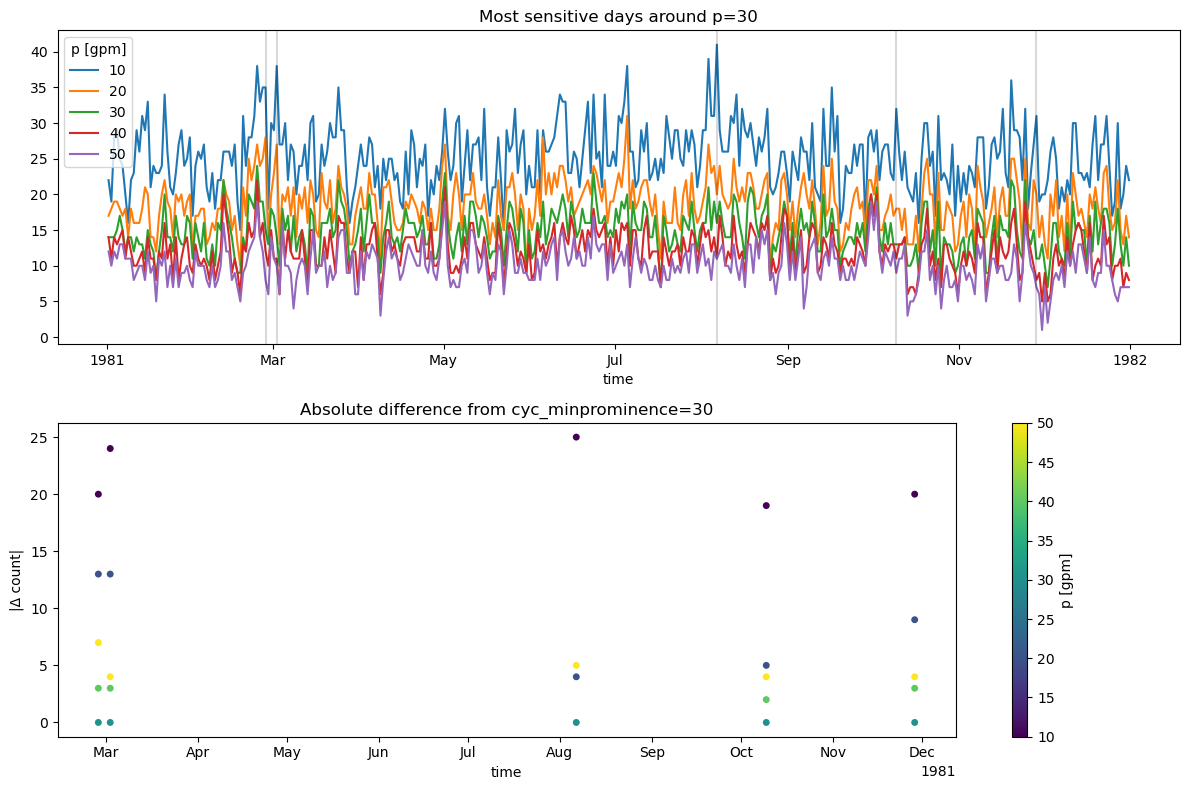

In [ ]:
# Find the n most sensitive days around cyc_minprominence=30
p = 30  # target parameter
n = 5  # Number of sensitive days

i = counts.get_index("p").get_loc(p)
x = counts  # .isel(p=[i-1, i, i+1])

# Difference from chosen cyc_minprominence (p)
diff = abs(x - x.sel(p=p))
# n days with largest difference
d = diff.max("p")
days = d.sortby(d, ascending=False).time[:n]
print(days.values)

# Values and differences on those days
out = x.sel(time=days)
out_diff = diff.sel(time=days)
print("Counts:", out)
print(f"Absolute difference from cyc_minprominence={p}", out_diff)

# Plot counts
fig, ax = plt.subplots(2, 1, figsize=(12, 8))
x.plot.line(x="time", hue="p", ax=ax[0])
for day in days:
    ax[0].axvline(day.values, color="k", alpha=0.15)
ax[0].set_title(f"Most sensitive days around p={p}")

# Plot differences on selected days
out_diff.plot.scatter(x="time", hue="p", marker="o", ax=ax[1])
ax[1].set_title(f"Absolute difference from cyc_minprominence={p}")
ax[1].set_ylabel("|Δ count|")

plt.tight_layout()
plt.savefig(f"{path_fig}/cyclone_500hpa_counts_daily.png")

These plots generally show that p=30, p=40, p=50 are fairly similar. The differences on these days are generally more related to p=10 and p=20.

# Plot geopotential height and cyclone contours on days sensitive to `cyc_minprominence`

In [22]:
days

<xarray.DataArray 'time' (time: 5)> Size: 40B
array(['1981-08-06T12:00:00.000000000', '1981-03-02T12:00:00.000000000',
       '1981-11-28T12:00:00.000000000', '1981-02-26T12:00:00.000000000',
       '1981-10-09T12:00:00.000000000'], dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 40B 1981-08-06T12:00:00 ... 1981-10-09T12:...
Attributes:
    long_name:  time

In [ ]:
# Open ERA5 geopotential (z) for the selected year
z = xr.open_mfdataset(
    f"/g/data/rt52/era5/pressure-levels/reanalysis/z/1981/z_era5_oper_pl_1981*.nc", chunks="auto"
)

# Select the n sensitive timesteps
z = z.sel(time=days)

# Convert to geopotential height
g = 9.80665  # m s-2
z = z.z / g
z.attrs["units"] = "gpm"

# Select variable at 500hPa
z = z.sel(level=500)
z

<xarray.Dataset> Size: 768MB
Dimensions:    (time: 5, level: 37, latitude: 721, longitude: 1440)
Coordinates:
  * longitude  (longitude) float32 6kB -180.0 -179.8 -179.5 ... 179.5 179.8
  * latitude   (latitude) float32 3kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * level      (level) int32 148B 1 2 3 5 7 10 20 ... 875 900 925 950 975 1000
  * time       (time) datetime64[ns] 40B 1981-08-06T12:00:00 ... 1981-10-09T1...
Data variables:
    z          (time, level, latitude, longitude) float32 768MB dask.array<chunksize=(5, 6, 486, 1080), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.6
    history:      2023-04-18 02:42:08 UTC+1000 by era5_replication_tools-1.12...
    license:      Licence to use Copernicus Products: https://apps.ecmwf.int/...
    summary:      ERA5 is the fifth generation ECMWF atmospheric reanalysis o...
    title:        ERA5 pressure-levels oper geopotential 19810101-19810131


cycmask: (time, lat, lon)
    Cyclone mask with different integers designating different cyclones

cycmeta: (time,nn,5)
    cycmeta data about each cyclone: (1) latitude and (2) longitude of centre, (3) minimum SLP, (4) SLP at the outermost contour, and (5) cyclone size.
    nn = 1000 (Maximum number of cyclones to be detected)

Compare with another value of cyc_minprominence 

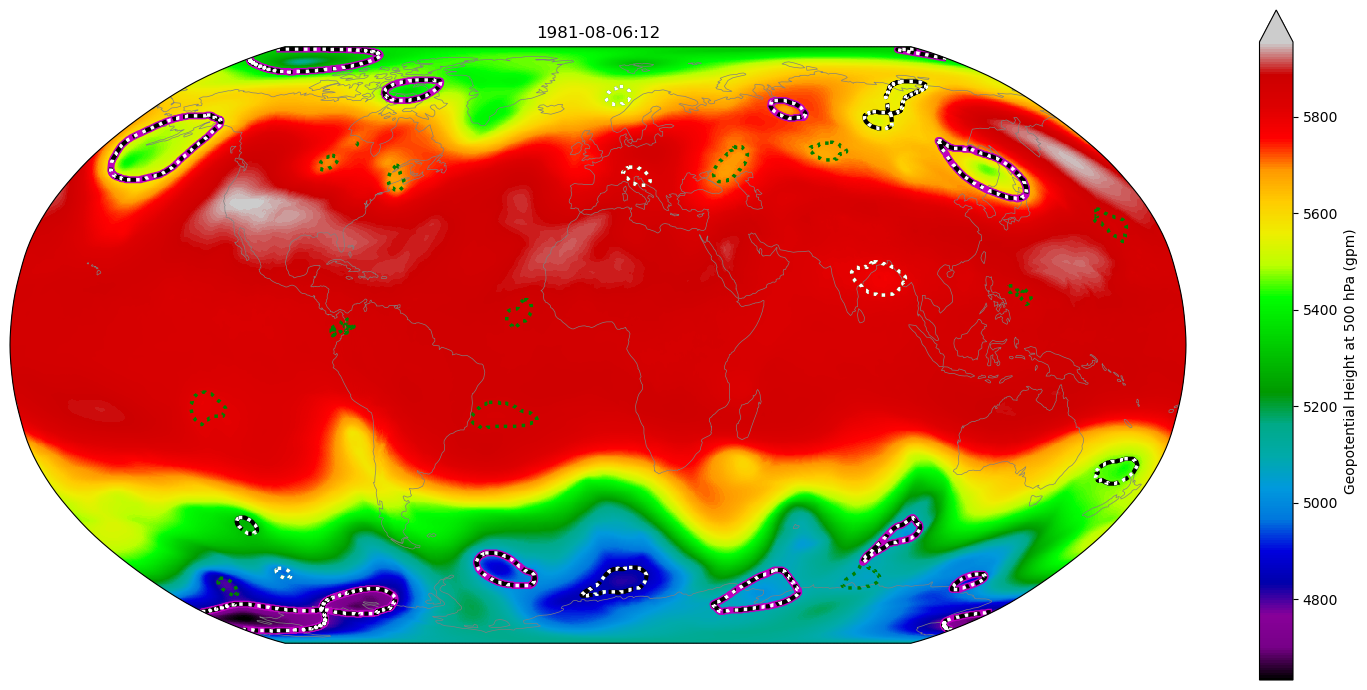

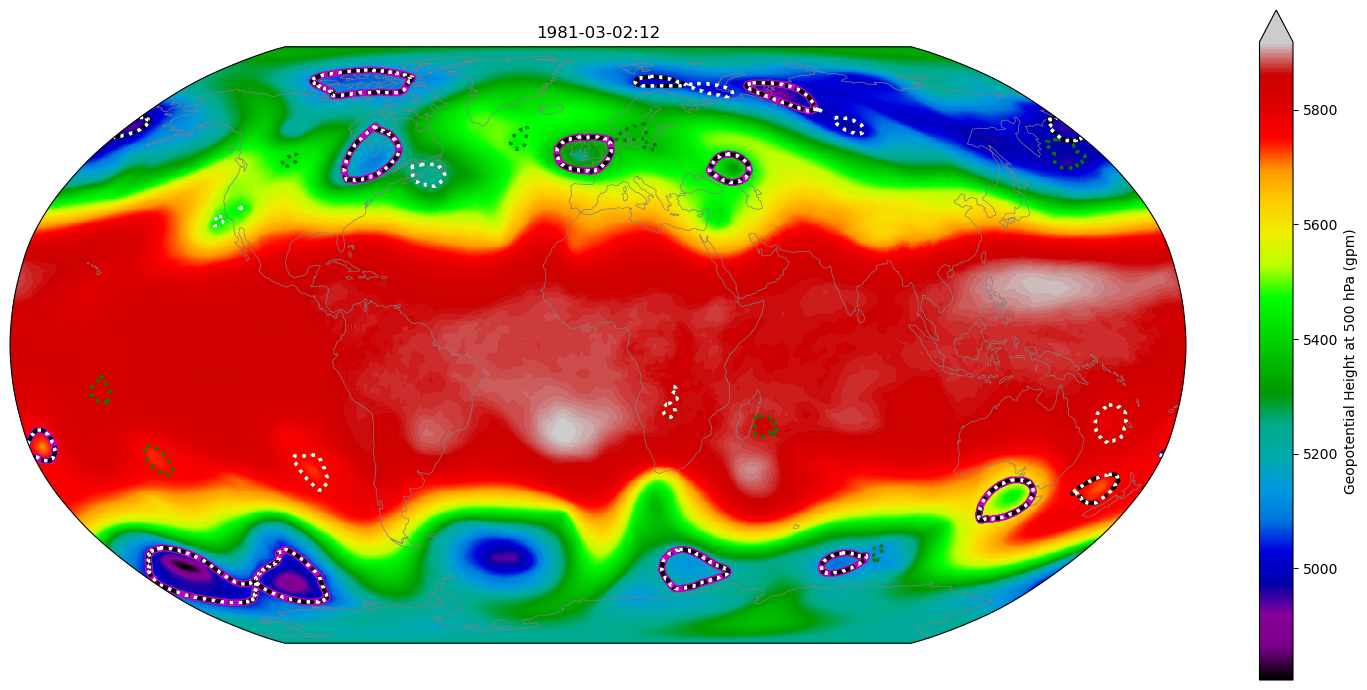

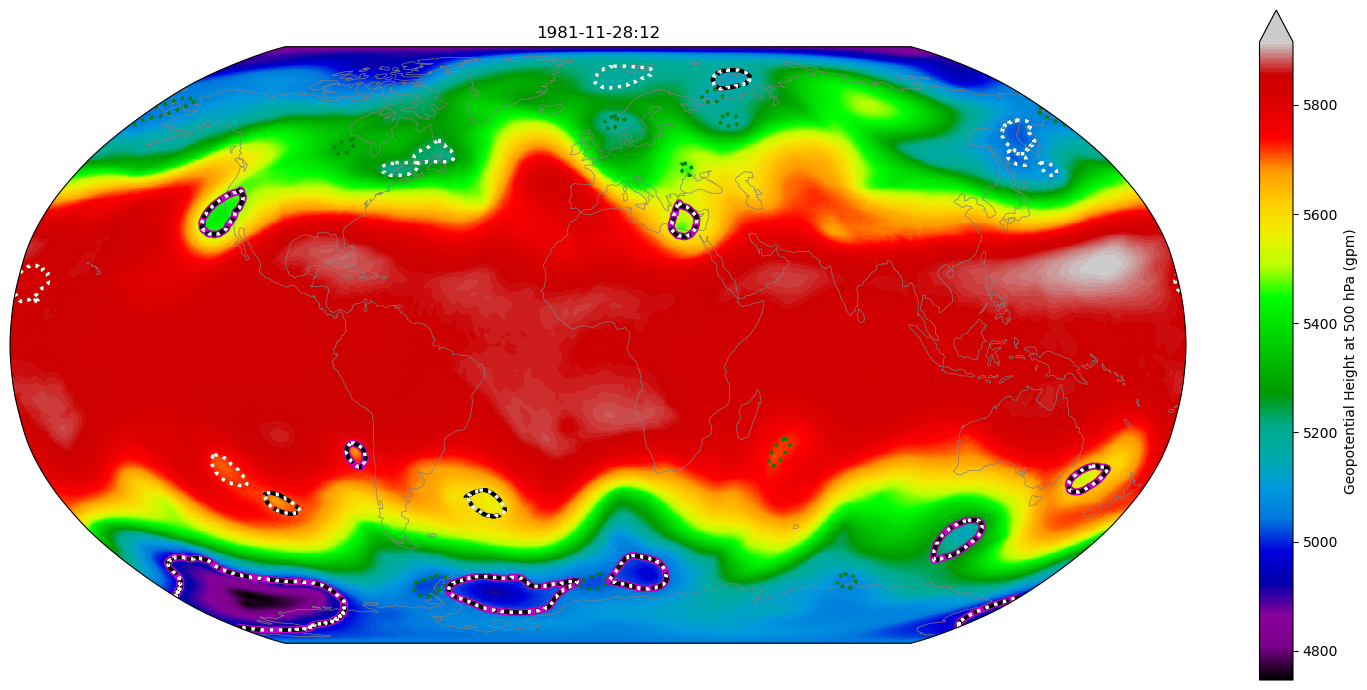

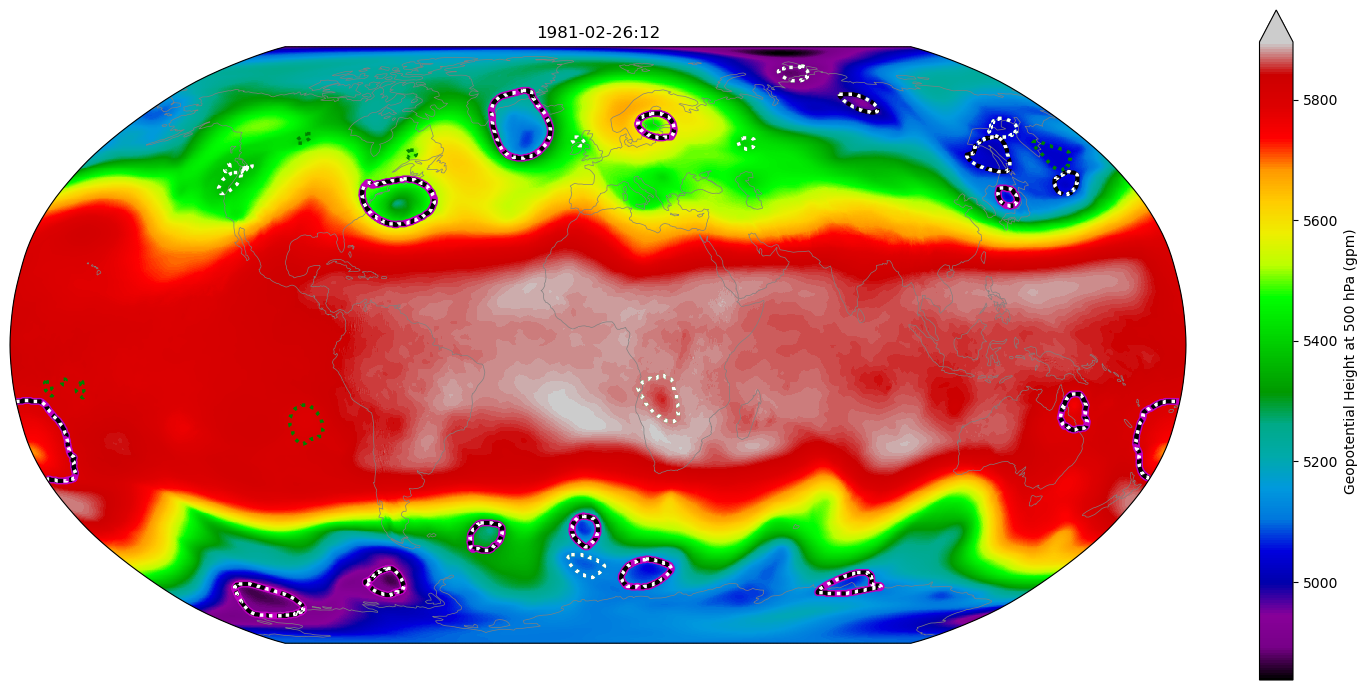

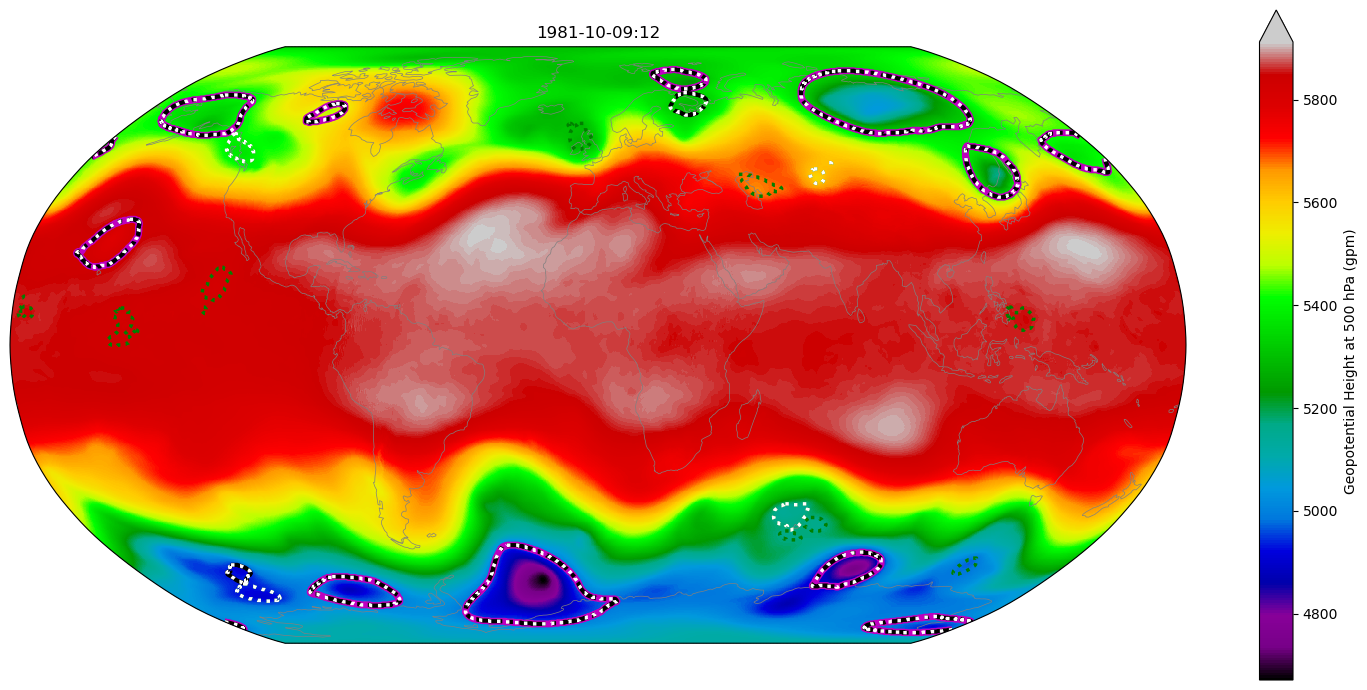

In [ ]:
# Plot cyclone contours for different min_prom values with geopotential height in the background.
for i, t in enumerate(z.time):
    fig, ax = plt.subplots(
        1,
        1,
        figsize=(15, 7),
        subplot_kw={"projection": ccrs.Robinson()},
    )
    ax.set_title(z.sel(time=t).time.dt.strftime("%Y-%m-%d:%H").item())
    ax.coastlines(color="gray", linewidth=0.5)
    cm = ax.pcolormesh(
        z.longitude,
        z.latitude,
        z.sel(time=t),
        cmap=plt.cm.nipy_spectral,
        transform=ccrs.PlateCarree(),
    )
    plt.colorbar(cm, extend="max", label="Geopotential Height at 500 hPa (gpm)")
    cf = ax.contour(
        ds_cyc.longitude,
        ds_cyc.latitude,
        xr.where(ds_cyc.sel(p=10) != 0, 1, 0).sel(time=t) * 1e3,
        colors="g",
        levels=[1],
        linestyles=":",
        linewidths=2.5,
        alpha=1,
        transform=ccrs.PlateCarree(),
    )

    cf = ax.contour(
        ds_cyc.longitude,
        ds_cyc.latitude,
        xr.where(ds_cyc.sel(p=40) != 0, 1, 0).sel(time=t) * 1e3,
        colors="m",
        levels=[1],
        # linestyles=":",
        linewidths=5,
        alpha=1,
        transform=ccrs.PlateCarree(),
    )
    cf = ax.contour(
        ds_cyc.longitude,
        ds_cyc.latitude,
        xr.where(ds_cyc.sel(p=30) != 0, 1, 0).sel(time=t) * 1e3,
        colors="k",
        levels=[1],
        linestyles="-.",
        linewidths=3,
        alpha=1,
        transform=ccrs.PlateCarree(),
    )
    cf = ax.contour(
        ds_cyc.longitude,
        ds_cyc.latitude,
        xr.where(ds_cyc.sel(p=20) != 0, 1, 0).sel(time=t) * 1e3,
        colors="w",
        levels=[1],
        linestyles=":",
        linewidths=2.5,
        alpha=1,
        transform=ccrs.PlateCarree(),
    )
    plt.tight_layout()
    plt.savefig(
        f'{path_fig}/cyclone_500hpa_p_sensitivity_{z.sel(time=t).time.dt.strftime("%Y%m%d").item()}.png'
    )
    plt.show()